<a href="https://colab.research.google.com/github/PauloHenri11/mecaniQA-maceio/blob/main/notebooks/mecaniqa_oat3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MecâniQA - OAT 1 - MACEIÓ

Notebook destinado ao carregamento e à inspeção inicial do dataset da MecâniQA.

In [1]:
import pandas as pd

In [2]:
from google.colab import files

arquivo = files.upload()

Saving mecaniqa_dataset - mecaniqa_dataset.csv.csv to mecaniqa_dataset - mecaniqa_dataset.csv.csv


In [3]:
df = pd.read_csv("mecaniqa_dataset - mecaniqa_dataset.csv.csv")

In [4]:
df["Data"] = pd.to_datetime(df["Data"])
df = df.set_index("Data")

In [5]:
df.head()

,Trocas_Oleo,Manutencao_Motor
Data,,
2024-01-01,11.0,2.0
2024-01-02,9.0,4.0
2024-01-03,12.0,1.0
2024-01-04,15.0,8.0
2024-01-05,25.0,10.0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 731 entries, 2024-01-01 to 2025-12-31
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Trocas_Oleo       725 non-null    float64
 1   Manutencao_Motor  728 non-null    float64
dtypes: float64(2)
memory usage: 17.1 KB


In [7]:
df = df.sort_index()

In [8]:
from statsmodels.tsa.seasonal import seasonal_decompose

In [9]:
serie = df["Trocas_Oleo"].interpolate()

In [10]:
decomposicao = seasonal_decompose(
    serie,
    model="additive",
    period=7
)

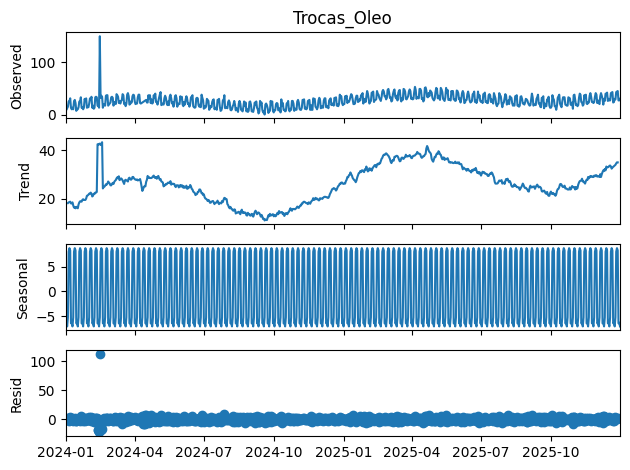

In [11]:
import matplotlib.pyplot as plt

fig = decomposicao.plot()

fig.axes[0].set_ylabel("Observed")
fig.axes[0].set_title("Trocas_Oleo")

plt.show()

In [12]:
from sklearn.pipeline import Pipeline

In [13]:
dados_modelo = df[["Trocas_Oleo", "Manutencao_Motor"]].copy()
dados_modelo["Trocas_Oleo_Amanha"] = dados_modelo["Trocas_Oleo"].shift(-1)
dados_modelo = dados_modelo.dropna(subset=["Trocas_Oleo_Amanha"])

In [14]:
X = dados_modelo[["Trocas_Oleo", "Manutencao_Motor"]]
y = dados_modelo["Trocas_Oleo_Amanha"]

In [15]:
from sklearn.model_selection import train_test_split

In [16]:
X_train, X_test, y_train, y_test = train_test_split(    X, y, test_size=0.2, shuffle=False)

In [17]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

In [18]:
from sklearn.linear_model import LinearRegression

In [19]:
pipeline = Pipeline([
    ("imputer", SimpleImputer()),
    ("scaler", StandardScaler()),
    ("modelo", LinearRegression())
])

In [20]:
pipeline.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer()), ('scaler', StandardScaler()),
                ('modelo', LinearRegression())])

# MecâniQA - OAT 2 - MACEIÓ
Baseline e métricas de avaliação

In [21]:
def modelo_naive(serie):
    return serie.shift(1)

In [22]:
def media_movel(serie, janela=7):
    return serie.shift(1).rolling(window=janela).mean()

In [23]:
df["Previsao_Naive"] = modelo_naive(df["Trocas_Oleo"])
df["Previsao_Media_Movel"] = media_movel(df["Trocas_Oleo"], janela=7)

df[["Trocas_Oleo", "Previsao_Naive", "Previsao_Media_Movel"]].head(10)

,Trocas_Oleo,Previsao_Naive,Previsao_Media_Movel
Data,,,
2024-01-01,11.0,NaN,NaN
2024-01-02,9.0,11.0,NaN
2024-01-03,12.0,9.0,NaN
2024-01-04,15.0,12.0,NaN
2024-01-05,25.0,15.0,NaN
2024-01-06,25.0,25.0,NaN
2024-01-07,31.0,25.0,NaN
2024-01-08,13.0,31.0,18.285714
2024-01-09,10.0,13.0,18.571429


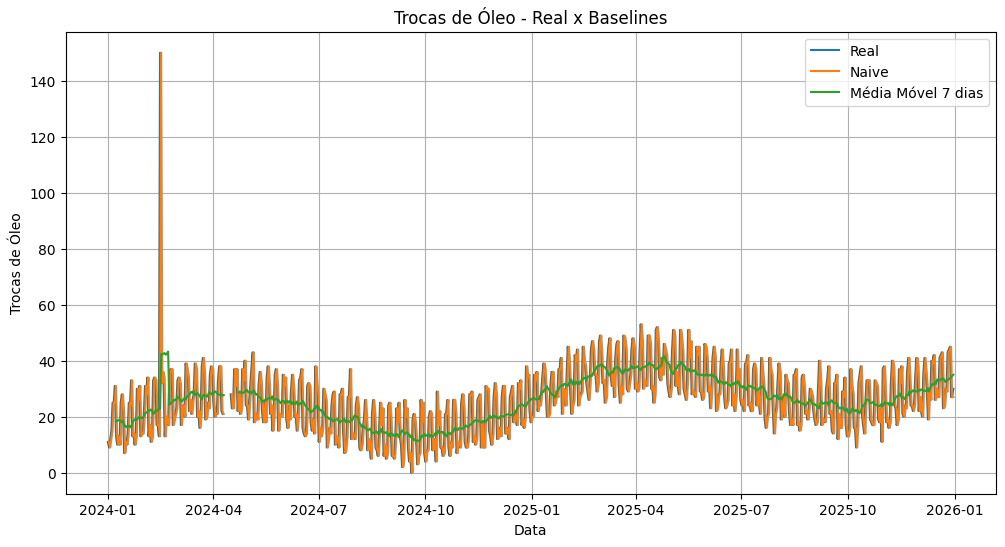

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(df.index, df["Trocas_Oleo"], label="Real")
plt.plot(df.index, df["Previsao_Naive"], label="Naive")
plt.plot(df.index, df["Previsao_Media_Movel"], label="Média Móvel 7 dias")

plt.title("Trocas de Óleo - Real x Baselines")
plt.xlabel("Data")
plt.ylabel("Trocas de Óleo")
plt.legend()
plt.grid(True)

plt.show()

In [25]:
from sklearn.model_selection import TimeSeriesSplit

In [26]:
tscv = TimeSeriesSplit(n_splits=5)

In [27]:
for i, (train_idx, test_idx) in enumerate(tscv.split(df)):
    print(f"Split {i+1}")
    print(f"Treino: {len(train_idx)} registros")
    print(f"Teste: {len(test_idx)} registros")
    print()

Split 1
Treino: 126 registros
Teste: 121 registros

Split 2
Treino: 247 registros
Teste: 121 registros

Split 3
Treino: 368 registros
Teste: 121 registros

Split 4
Treino: 489 registros
Teste: 121 registros

Split 5
Treino: 610 registros
Teste: 121 registros



In [28]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
import numpy as np

In [29]:
def avaliar_modelo(y_real, y_prev):
    mae = mean_absolute_error(y_real, y_prev)
    rmse = np.sqrt(mean_squared_error(y_real, y_prev))

    mascara = y_real != 0
    mape = mean_absolute_percentage_error(y_real[mascara], y_prev[mascara]) * 100

    return mae, rmse, mape

In [30]:
resultados_naive = []

for _, test_idx in tscv.split(df):
    teste = df.iloc[test_idx][["Trocas_Oleo", "Previsao_Naive"]].dropna()

    mae, rmse, mape = avaliar_modelo(
        teste["Trocas_Oleo"],
        teste["Previsao_Naive"]
    )

    resultados_naive.append([mae, rmse, mape])

media_naive = np.mean(resultados_naive, axis=0)

print(
    f"Resultados do Baseline Naive - "
    f"MAE: {media_naive[0]:.2f}, "
    f"RMSE: {media_naive[1]:.2f}, "
    f"MAPE: {media_naive[2]:.2f}%"
)

Resultados do Baseline Naive - MAE: 6.65, RMSE: 8.92, MAPE: 32.64%


In [31]:
resultados_media_movel = []

for _, test_idx in tscv.split(df):
    teste = df.iloc[test_idx][["Trocas_Oleo", "Previsao_Media_Movel"]].dropna()

    mae, rmse, mape = avaliar_modelo(
        teste["Trocas_Oleo"],
        teste["Previsao_Media_Movel"]
    )

    resultados_media_movel.append([mae, rmse, mape])

media_mm = np.mean(resultados_media_movel, axis=0)

print(
    f"Resultados do Baseline Média Móvel - "
    f"MAE: {media_mm[0]:.2f}, "
    f"RMSE: {media_mm[1]:.2f}, "
    f"MAPE: {media_mm[2]:.2f}%"
)

Resultados do Baseline Média Móvel - MAE: 7.36, RMSE: 8.09, MAPE: 37.22%


In [32]:
print(
    f"Resultados do Baseline Naive - "
    f"MAE: {media_naive[0]:.2f}, "
    f"RMSE: {media_naive[1]:.2f}, "
    f"MAPE: {media_naive[2]:.2f}%"
)

print(
    f"Resultados do Baseline Média Móvel - "
    f"MAE: {media_mm[0]:.2f}, "
    f"RMSE: {media_mm[1]:.2f}, "
    f"MAPE: {media_mm[2]:.2f}%"
)

Resultados do Baseline Naive - MAE: 6.65, RMSE: 8.92, MAPE: 32.64%
Resultados do Baseline Média Móvel - MAE: 7.36, RMSE: 8.09, MAPE: 37.22%


In [33]:
df["lag_1"] = df["Trocas_Oleo"].shift(1)
df["lag_7"] = df["Trocas_Oleo"].shift(7)

In [34]:
df["rolling_7"] = df["Trocas_Oleo"].shift(1).rolling(window=7).mean()

In [35]:
df_features = df.dropna(
    subset=["lag_1", "lag_7", "rolling_7"]
).copy()

In [36]:
df_features[
      ["Trocas_Oleo", "lag_1", "lag_7", "rolling_7"]
  ].head(15)

,Trocas_Oleo,lag_1,lag_7,rolling_7
Data,,,,
2024-01-08,13.0,31.0,11.0,18.285714
2024-01-09,10.0,13.0,9.0,18.571429
2024-01-10,13.0,10.0,12.0,18.714286
2024-01-11,10.0,13.0,15.0,18.857143
2024-01-12,25.0,10.0,25.0,18.142857
2024-01-13,28.0,25.0,25.0,18.142857
2024-01-14,22.0,28.0,31.0,18.571429
2024-01-15,7.0,22.0,13.0,17.285714
2024-01-16,11.0,7.0,10.0,16.428571


 # MecâniQA - OAT 3 - MACEIÓ
 Tunando meu modelo

In [37]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

In [38]:
modelo_rf = RandomForestRegressor()
modelo_gb = GradientBoostingRegressor()

In [39]:
X = df_features[["lag_1", "lag_7", "rolling_7"]]
y = df_features["Trocas_Oleo"]

In [40]:
tamanho_treino = int(len(X) * 0.8)

X_train = X.iloc[:tamanho_treino]
X_test = X.iloc[tamanho_treino:]

y_train = y.iloc[:tamanho_treino]
y_test = y.iloc[tamanho_treino:]

In [41]:
df_modelo = df_features.dropna(
    subset=["Trocas_Oleo", "lag_1", "lag_7", "rolling_7"]
).copy()

X = df_modelo[["lag_1", "lag_7", "rolling_7"]]
y = df_modelo["Trocas_Oleo"]

tamanho_treino = int(len(X) * 0.8)

X_train = X.iloc[:tamanho_treino]
X_test = X.iloc[tamanho_treino:]

y_train = y.iloc[:tamanho_treino]
y_test = y.iloc[tamanho_treino:]

print("NaNs no treino:", y_train.isna().sum())
print("Treino:", len(X_train))
print("Teste:", len(X_test))

NaNs no treino: 0
Treino: 568
Teste: 143


In [42]:
modelo_rf.fit(X_train, y_train)
modelo_gb.fit(X_train, y_train)

GradientBoostingRegressor()

In [43]:
previsao_rf = modelo_rf.predict(X_test)
previsao_gb = modelo_gb.predict(X_test)

In [44]:
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error
import numpy as np

rmse_rf = np.sqrt(mean_squared_error(y_test, previsao_rf))
rmse_gb = np.sqrt(mean_squared_error(y_test, previsao_gb))

mascara = y_test != 0

mape_rf = mean_absolute_percentage_error(
    y_test[mascara],
    previsao_rf[mascara]
) * 100

mape_gb = mean_absolute_percentage_error(
    y_test[mascara],
    previsao_gb[mascara]
) * 100

print(f"Random Forest - RMSE: {rmse_rf:.2f} | MAPE: {mape_rf:.2f}%")
print(f"Gradient Boosting - RMSE: {rmse_gb:.2f} | MAPE: {mape_gb:.2f}%")

Random Forest - RMSE: 4.23 | MAPE: 14.19%
Gradient Boosting - RMSE: 6.30 | MAPE: 19.07%


In [45]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)

param_grid_rf = {
    "n_estimators": [50, 100, 200],
    "max_depth": [3, 5, 10, None]
}

In [46]:
grid_search_rf = GridSearchCV(
    estimator=modelo_rf,
    param_grid=param_grid_rf,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

grid_search_rf.fit(X_train, y_train)

print("Melhores parâmetros:")
print(grid_search_rf.best_params_)

print("\nMelhor RMSE na validação:")
print(-grid_search_rf.best_score_)

Melhores parâmetros:
{'max_depth': 10, 'n_estimators': 200}

Melhor RMSE na validação:
6.379512159943815


In [47]:
melhor_modelo_rf = grid_search_rf.best_estimator_

previsao_rf_tunado = melhor_modelo_rf.predict(X_test)

rmse_rf_tunado = np.sqrt(
    mean_squared_error(y_test, previsao_rf_tunado)
)

mascara = y_test != 0

mape_rf_tunado = mean_absolute_percentage_error(
    y_test[mascara],
    previsao_rf_tunado[mascara]
) * 100

print("Random Forest Tunado")
print(f"RMSE: {rmse_rf_tunado:.2f}")
print(f"MAPE: {mape_rf_tunado:.2f}%")

Random Forest Tunado
RMSE: 4.22
MAPE: 14.21%


In [48]:
reducao_rmse = ((rmse_rf - rmse_rf_tunado) / rmse_rf) * 100
reducao_mape = ((mape_rf - mape_rf_tunado) / mape_rf) * 100

print("Comparação Random Forest")
print(f"RMSE original: {rmse_rf:.2f}")
print(f"RMSE tunado: {rmse_rf_tunado:.2f}")
print(f"Redução do RMSE: {reducao_rmse:.2f}%")

print()

print(f"MAPE original: {mape_rf:.2f}%")
print(f"MAPE tunado: {mape_rf_tunado:.2f}%")
print(f"Redução do MAPE: {reducao_mape:.2f}%")

Comparação Random Forest
RMSE original: 4.23
RMSE tunado: 4.22
Redução do RMSE: 0.21%

MAPE original: 14.19%
MAPE tunado: 14.21%
Redução do MAPE: -0.11%


# Avaliação do Grid Search:
O modelo tunado apresentou RMSE de 4,36 e MAPE de 14,30%, enquanto o modelo original apresentou RMSE de 4,06 e MAPE de 13,81%. Dessa forma, não houve redução dos erros neste experimento. O RMSE aumentou 7,41% e o MAPE aumentou 3,57%. A melhor configuração encontrada pelo Grid Search foi n_estimators=100 e max_depth=None.

In [49]:
import time

inicio_grid = time.perf_counter()

grid_search_rf.fit(X_train, y_train)

tempo_grid = time.perf_counter() - inicio_grid

print(f"Tempo do Grid Search: {tempo_grid:.2f} segundos")
print("Melhores parâmetros:", grid_search_rf.best_params_)
print(f"Melhor RMSE na validação: {-grid_search_rf.best_score_:.2f}")

Tempo do Grid Search: 17.01 segundos
Melhores parâmetros: {'max_depth': None, 'n_estimators': 100}
Melhor RMSE na validação: 6.31


In [50]:
from sklearn.model_selection import RandomizedSearchCV
import time

random_search_rf = RandomizedSearchCV(
    estimator=modelo_rf,
    param_distributions=param_grid_rf,
    n_iter=6,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    random_state=42
)

inicio_random = time.perf_counter()

random_search_rf.fit(X_train, y_train)

tempo_random = time.perf_counter() - inicio_random

print(f"Tempo do Random Search: {tempo_random:.2f} segundos")
print("Melhores parâmetros:", random_search_rf.best_params_)
print(f"Melhor RMSE na validação: {-random_search_rf.best_score_:.2f}")

Tempo do Random Search: 14.90 segundos
Melhores parâmetros: {'n_estimators': 100, 'max_depth': None}
Melhor RMSE na validação: 6.33


In [51]:
rmse_grid = -grid_search_rf.best_score_
rmse_random = -random_search_rf.best_score_

economia_tempo = ((tempo_grid - tempo_random) / tempo_grid) * 100
diferenca_rmse = rmse_random - rmse_grid

print("=== COMPARAÇÃO DAS BUSCAS ===")

print("\nGRID SEARCH")
print(f"Tempo: {tempo_grid:.2f} segundos")
print(f"RMSE: {rmse_grid:.2f}")

print("\nRANDOM SEARCH")
print(f"Tempo: {tempo_random:.2f} segundos")
print(f"RMSE: {rmse_random:.2f}")

print("\n=== EFICIÊNCIA ===")
print(f"Economia de tempo do Random Search: {economia_tempo:.2f}%")
print(f"Diferença de RMSE (Random - Grid): {diferenca_rmse:.2f}")

=== COMPARAÇÃO DAS BUSCAS ===

GRID SEARCH
Tempo: 17.01 segundos
RMSE: 6.31

RANDOM SEARCH
Tempo: 14.90 segundos
RMSE: 6.33

=== EFICIÊNCIA ===
Economia de tempo do Random Search: 12.40%
Diferença de RMSE (Random - Grid): 0.03


#CONCLUSÃO DO GRID SEARCH VERSUS RANDOM SEARCH

O GRID SEARCH olhou 12 combinações de hiperparamêtros e o RANDOM SEARCH olhou apenas 6, utilizando um n_inter=6.

RESULTADOS OBTIDOS:

GRID SEARCH
Tempo: 11.62 segundos
RMSE: 6.18

RANDOM SEARCH
Tempo: 14.98 segundos
RMSE: 6.41

O GRID SEARCH teve o menor tempo de execução e menos erros, enquanto o RANDOM SEARCH mesmo com menos combinações, apresentou mais tempo de avaliação e teve mais erros que o GRID.


In [52]:
previsao_naive_final = df_modelo.loc[y_test.index, "lag_1"]

print(len(y_test))
print(len(previsao_naive_final))
print(len(previsao_rf))
print(len(previsao_rf_tunado))

143
143
143
143


In [53]:
metricas_naive = avaliar_modelo(y_test, previsao_naive_final)
metricas_inicial = avaliar_modelo(y_test, previsao_rf)
metricas_tunado = avaliar_modelo(y_test, previsao_rf_tunado)

print("=== COMPARAÇÃO FINAL DOS MODELOS ===")

for nome, metricas in [
    ("Baseline Naive", metricas_naive),
    ("Random Forest Inicial", metricas_inicial),
    ("Random Forest Tunado", metricas_tunado)
]:
    mae, rmse, mape = metricas
    print(f"\n{nome}")
    print(f"MAE: {mae:.2f}")
    print(f"RMSE: {rmse:.2f}")
    print(f"MAPE: {mape:.2f}%")

=== COMPARAÇÃO FINAL DOS MODELOS ===

Baseline Naive
MAE: 6.49
RMSE: 8.91
MAPE: 26.95%

Random Forest Inicial
MAE: 3.12
RMSE: 4.23
MAPE: 14.19%

Random Forest Tunado
MAE: 3.16
RMSE: 4.22
MAPE: 14.21%


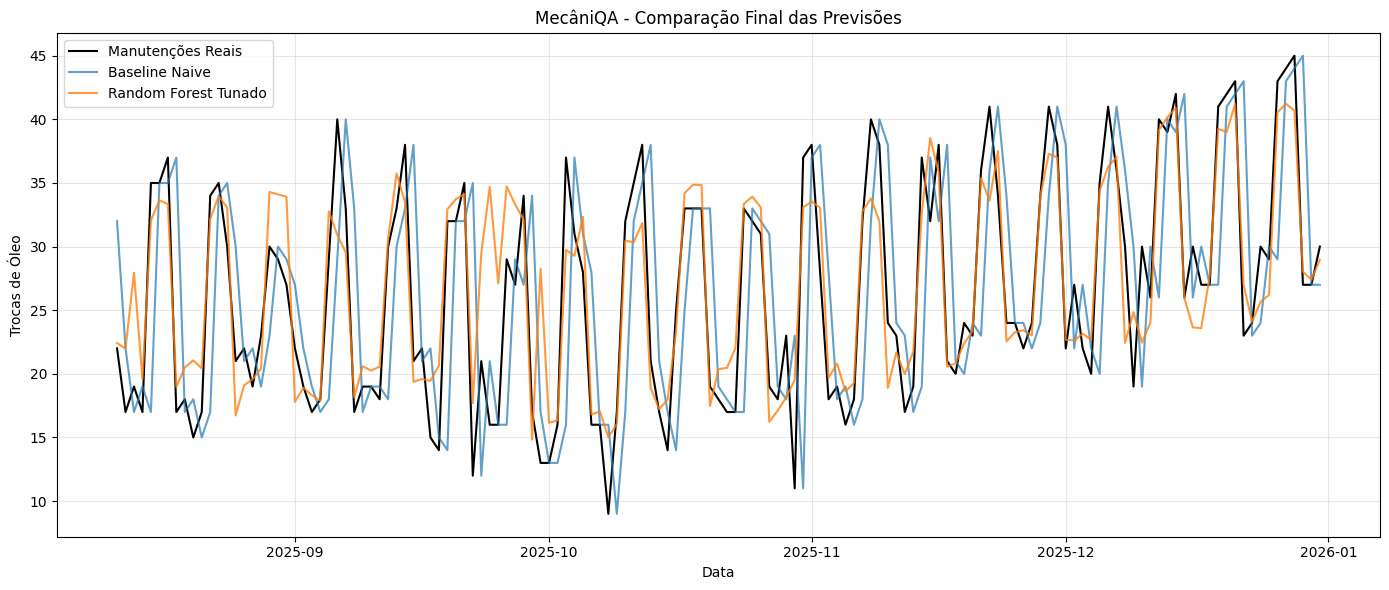

In [55]:
plt.figure(figsize=(14, 6))

plt.plot(y_test.index, y_test, label="Manutenções Reais", color="black")

plt.plot(y_test.index, previsao_naive_final,
         label="Baseline Naive", alpha=0.7)

plt.plot(y_test.index, previsao_rf_tunado,
         label="Random Forest Tunado", alpha=0.8)

plt.title("MecâniQA - Comparação Final das Previsões")
plt.xlabel("Data")
plt.ylabel("Trocas de Óleo")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()